# Part 3 — Validating Drivers Against Known Regulators and TF Activity

Notebook 2 gave us a list of candidate "driver genes" per lineage, computed purely from
correlation: does a gene's expression in progenitor cells predict which fate those cells are
heading towards? That's a useful, cheap signal, but correlation alone can't tell us whether a
gene is a **transcription factor actually steering the decision**, or just a gene that happens
to be switched on alongside the real driver.

This notebook checks the notebook-2 driver lists two ways:

1. **Against the literature.** We fix a short list of transcription factors already known, from
   decades of mouse pancreas developmental biology, to specify each endocrine fate — *before*
   looking at any of our results — and see where they land in our data-driven ranking.
2. **Against independent TF-activity inference.** A gene's own expression level is a weak proxy
   for whether it's functionally *active*: a TF's mRNA can be present but its protein inactive,
   or vice versa. **CollecTRI** is a curated database of TF → target-gene relationships; feeding
   it into **decoupler**'s ULM method turns raw gene expression into a per-cell "TF activity
   score" for every TF with enough curated targets in our data. If a TF's *activity* correlates
   with a fate the way its curated targets predict, that's a more mechanistic signal than
   expression correlation alone.

We then compare the two views (expression-based vs. activity-based) side by side, flag where
they agree or disagree, and try to explain the disagreements.

**Honest limitations up front:** correlation is not causation anywhere in this notebook; CollecTRI
is a human-curated resource that we translate to mouse via orthology, so some mouse-specific
regulation it won't capture; and TF-activity inference assumes a TF's curated target genes behave
the same way in this developing-pancreas system as in whatever tissues/studies CollecTRI's edges
came from — not guaranteed.

## 1. Setup and known regulators

We load the AnnData saved by notebook 2 (fate probabilities, latent time, etc.) and the
**progenitor-restricted** driver tables -- not the `_allcells` versions -- since those are the
ones notebook 2 flagged as the trustworthy, canonical set for downstream use.

In [1]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import scanpy as sc
import scvelo as scv
import matplotlib.pyplot as plt
import scipy.stats as ss

DATA_DIR = Path("../data")
RESULTS_DIR = Path("../results")
FIG_DIR = Path("../figures")
FIG_DIR.mkdir(exist_ok=True)

adata = sc.read_h5ad(DATA_DIR / "pancreas_fates.h5ad")

# Progenitor-restricted driver tables from notebook 2 (the canonical set for step 3) --
# explicitly NOT the "_allcells" versions, which are contaminated by the Beta fate-probability
# skew in already-differentiated cells.
driver_df = pd.read_csv(RESULTS_DIR / "lineage_drivers_all_genes.csv", index_col=0)

lineage_names = ["Delta", "Epsilon", "Alpha", "Beta"]  # matches adata.obsm["lineages_fwd"] column order
progenitor_clusters_for_drivers = ["Ngn3 high EP", "Pre-endocrine"]  # same clusters notebook 2 used

fate_probs = pd.DataFrame(
    np.asarray(adata.obsm["lineages_fwd"]), columns=lineage_names, index=adata.obs_names
)
progenitor_mask = adata.obs["clusters"].isin(progenitor_clusters_for_drivers).to_numpy()

print(f"AnnData: {adata.n_obs} cells x {adata.n_vars} genes")
print(f"Driver table: {driver_df.shape[0]} genes x {driver_df.shape[1]} columns")
print(f"Progenitor cells for correlation (Ngn3 high EP + Pre-endocrine): {progenitor_mask.sum()}")

AnnData: 3696 cells x 7197 genes
Driver table: 7197 genes x 20 columns
Progenitor cells for correlation (Ngn3 high EP + Pre-endocrine): 1234


### Known regulators, fixed in advance

These are defined *before* we look at any CellRank or CollecTRI results below, so that
"where does the literature TF rank" is a genuine check rather than something we tuned after the
fact. Sources are noted per gene/group as code comments -- citations we're confident about get an
author/year; a few entries (`Irx1`, `Irx2`, `Pou3f4`, `Fev`) are supported mainly by pancreas
single-cell studies (including this dataset's own source paper, Bastidas-Ponce et al. 2019,
*Development*) rather than classical knockout literature, which is noted explicitly rather than
implied to be equally strong evidence.

In [2]:
# Beta-cell master regulators -- classical mouse knockout literature:
#   Pdx1:   Jonsson et al. 1994, Nature -- pancreas agenesis in Pdx1-null mice
#   Nkx6-1: Sander et al. 2000, Development -- required for beta-cell formation downstream of Nkx2-2
#   Mafa:   Beta-cell maturation factor (Olbrot et al. 2002; Matsuoka et al. 2004)
#   Pax4:   Sosa-Pineda et al. 1997, Nature -- required for beta (and delta) cell differentiation
#   Nkx2-2: Sussel et al. 1998, Development -- required for beta-cell differentiation
BETA_REGULATORS = ["Pdx1", "Nkx6-1", "Mafa", "Pax4", "Nkx2-2"]

# Alpha-cell master regulators:
#   Arx:    Collombat et al. 2003, Genes Dev -- specifies alpha vs. beta/delta fate (opposes Pax4)
#   Mafb:   Artner et al. 2006, Diabetes -- activates glucagon in developing alpha (and beta) cells
#   Irx1/2: Alpha-lineage-associated in pancreas endocrinogenesis scRNA-seq, incl. this dataset's
#           own source paper (Bastidas-Ponce et al. 2019, Development) -- weaker evidence than the
#           classical knockout literature above
#   Pou3f4: Reported as an alpha-lineage-associated TF in pancreas endocrinogenesis scRNA-seq
#           studies (incl. the CellRank/scVelo pancreas tutorial) -- weaker evidence, flagged here
BETA = BETA_REGULATORS
ALPHA_REGULATORS = ["Arx", "Mafb", "Irx1", "Irx2", "Pou3f4"]

# Delta-cell regulator:
#   Hhex: Reported as a delta-cell regulator in islet scRNA-seq/lineage-tracing studies; much less
#         extensively characterized by classical knockouts than the beta/alpha TFs above
DELTA_REGULATORS = ["Hhex"]

# Shared endocrine-progenitor regulators -- act upstream of all four fates, not specific to one:
#   Neurog3 (Ngn3): Gradwohl et al. 2000, PNAS -- required for all four endocrine lineages
#   Neurod1:        Naya et al. 1997, Genes Dev -- acts downstream of Neurog3
#   Fev:            Reported as an Ngn3+ endocrine-progenitor marker in islet scRNA-seq studies
SHARED_PROGENITOR_REGULATORS = ["Neurog3", "Neurod1", "Fev"]

KNOWN_REGULATORS = {
    "Beta": BETA_REGULATORS,
    "Alpha": ALPHA_REGULATORS,
    "Delta": DELTA_REGULATORS,
}

print("Known regulators fixed in advance:")
for lineage, genes in KNOWN_REGULATORS.items():
    print(f"  {lineage}: {genes}")
print(f"  Shared endocrine progenitor: {SHARED_PROGENITOR_REGULATORS}")

Known regulators fixed in advance:
  Beta: ['Pdx1', 'Nkx6-1', 'Mafa', 'Pax4', 'Nkx2-2']
  Alpha: ['Arx', 'Mafb', 'Irx1', 'Irx2', 'Pou3f4']
  Delta: ['Hhex']
  Shared endocrine progenitor: ['Neurog3', 'Neurod1', 'Fev']


### Where do the known regulators rank in CellRank's (progenitor-restricted) driver list?

For each lineage-specific regulator we look up its rank when `driver_df` is sorted by that
lineage's correlation, descending (rank 1 = strongest positive correlation, out of 7197 genes).
For the shared progenitor regulators we report their rank in all four lineages, since they're not
expected to specifically predict any one fate.

In [3]:
def driver_rank(gene, lineage):
    """1-indexed rank of `gene` in driver_df sorted by {lineage}_corr, descending. None if absent."""
    col = f"{lineage}_corr"
    if gene not in driver_df.index:
        return None, None
    order = driver_df[col].rank(ascending=False, method="min")
    return int(order.loc[gene]), float(driver_df.loc[gene, col])


print("Lineage-specific known regulators -- rank in CellRank's progenitor-restricted driver list:")
rows = []
for lineage, genes in KNOWN_REGULATORS.items():
    for gene in genes:
        rank, corr = driver_rank(gene, lineage)
        rows.append({"lineage": lineage, "gene": gene, "rank": rank, "corr": corr})
known_reg_ranks = pd.DataFrame(rows)
known_reg_ranks

Lineage-specific known regulators -- rank in CellRank's progenitor-restricted driver list:


,lineage,gene,rank,corr
0,Beta,Pdx1,8.0,0.218036
1,Beta,Nkx6-1,6.0,0.229963
2,Beta,Mafa,NaN,NaN
3,Beta,Pax4,40.0,0.126793
4,Beta,Nkx2-2,1076.0,0.036603
5,Alpha,Arx,1.0,0.320581
6,Alpha,Mafb,NaN,NaN
7,Alpha,Irx1,NaN,NaN
8,Alpha,Irx2,90.0,0.092133
9,Alpha,Pou3f4,NaN,NaN


In [4]:
print("Shared endocrine-progenitor regulators -- rank in EVERY lineage (not expected to be lineage-specific):")
rows = []
for gene in SHARED_PROGENITOR_REGULATORS:
    for lineage in lineage_names:
        rank, corr = driver_rank(gene, lineage)
        rows.append({"gene": gene, "lineage": lineage, "rank": rank, "corr": corr})
shared_reg_ranks = pd.DataFrame(rows)
shared_reg_ranks.pivot(index="gene", columns="lineage", values="rank")

Shared endocrine-progenitor regulators -- rank in EVERY lineage (not expected to be lineage-specific):


lineage,Alpha,Beta,Delta,Epsilon
gene,,,,
Fev,6884,518,1728,6292
Neurod1,3908,5211,2375,1588
Neurog3,18,394,7180,7117


**What this shows.**

- **Recovered well:** *Arx* is literally the #1 driver for Alpha (corr 0.32), *Hhex* is #1 for
  Delta (corr 0.57), and *Nkx6-1* (#6, corr 0.23) and *Pdx1* (#8, corr 0.22) both land in Beta's
  top 10 -- all four match the literature-fixed list closely.
- **Recovered, but far down the list:** *Pax4* is #40 for Beta (corr 0.13) and *Irx2* is #90 for
  Alpha (corr 0.09) -- present and positively correlated, but nowhere near the top.
- **Not recovered at all:** *Nkx2-2* -- despite being one of the best-established beta-cell
  regulators in the mouse knockout literature (Sussel et al. 1998) -- ranks **1076th** of 7197
  genes for Beta (corr 0.037, essentially noise). This is a reminder that correlation with
  eventual fate probability is not the same thing as developmental necessity: a gene can be
  essential for a fate while being expressed broadly and near-uniformly across progenitors
  regardless of which fate they're actually heading towards.
- **Not evaluable:** *Mafa*, *Mafb*, *Irx1* and *Pou3f4* -- 4 of the 11 lineage-specific known
  regulators -- aren't in our 7197-gene (HVG-filtered) panel at all, so they can't be checked this
  way; see Section 2 for the full missing-gene log.
- **Shared progenitor regulators don't behave neutrally.** We expected *Neurog3*, *Neurod1* and
  *Fev* to correlate weakly with every fate, since they mark the progenitor state itself rather
  than any one commitment. Instead each shows a distinct skew: *Neurog3* ranks a surprising
  **18th** for Alpha specifically (vs. 7180th and 7117th for Delta and Epsilon), and *Fev* ranks
  much better for Beta/Delta (518th, 1728th) than for Alpha/Epsilon (6884th, 6292th). This wasn't
  anticipated -- it suggests these "shared" markers' residual expression levels during the Ngn3+
  window already carry some lineage-bias signal in this dataset, which is worth keeping in mind
  rather than treating them as a clean negative control.

## 2. CollecTRI (mouse) via decoupler

**CollecTRI** is a curated database of transcription factor → target-gene interactions, each
signed (activating or repressing). We use the Python package **decoupler** to fetch it.

In [5]:
import decoupler as dc

print("decoupler version:", dc.version("decoupler"))

decoupler version: 2.1.4


**A note on the installed decoupler API (v2.x).** Recent decoupler reorganized its API into
submodules: network resources live under `dc.op` (e.g. `dc.op.collectri`), and enrichment/activity
methods live under `dc.mt` (e.g. `dc.mt.ulm`) -- this replaces the flat `dc.get_collectri()` /
`dc.run_ulm()` functions from decoupler 1.x. We use the current `dc.op.collectri(organism=...)`
and `dc.mt.ulm(...)` API throughout.

**A broken download URL, and the fix.** `dc.op.collectri(organism="mouse")` internally calls
`dc.op.translate()`, which downloads a human→mouse ortholog table from a hardcoded
`ftp.ebi.ac.uk` URL. That URL now 404s: HGNC (the data's source) migrated all HCOP bulk-download
files to a public Google Cloud Storage bucket, and the old FTP paths were retired. The fix is a
pure URL update, not a methodology change -- we replicate `translate()`'s exact logic (same
minimum-evidence filter, same one-to-many ortholog capping, reusing decoupler's own internal
helper function) and just point it at the ortholog table's current location.

In [6]:
from decoupler.op._translate import _translate as _dc_translate_one_to_many


def collectri_mouse(min_evidence: int = 3, one_to_many: int = 5) -> pd.DataFrame:
    """Mouse CollecTRI network, replicating dc.op.translate()'s logic with a working HCOP URL.

    decoupler's own `dc.op.translate()` hardcodes a now-dead ftp.ebi.ac.uk URL for the human-mouse
    ortholog table (HCOP). We download the same table from its current location (a public GCS
    bucket HGNC migrated to) and otherwise apply decoupler's exact translation steps.
    """
    hcop_url = "https://storage.googleapis.com/public-download-files/hcop/human_mouse_hcop_fifteen_column.txt.gz"
    map_df = pd.read_csv(hcop_url, sep="\t", low_memory=False)
    map_df["evidence"] = map_df["support"].apply(lambda x: len(str(x).split(",")))
    map_df = map_df[map_df["evidence"] >= min_evidence]
    map_df = map_df[["human_symbol", "mouse_symbol"]].rename(columns={"human_symbol": "source", "mouse_symbol": "target"})
    map_dict = map_df.groupby("source")["target"].apply(list).to_dict()

    human_net = dc.op.collectri(organism="human")
    mouse_net = human_net.copy()
    for col in ["source", "target"]:
        mouse_net = _dc_translate_one_to_many(resource=mouse_net, map_dict=map_dict, column=col, one_to_many=one_to_many)
    mouse_net = mouse_net.drop_duplicates(["source", "target"]).reset_index(drop=True)
    return mouse_net


mouse_net = collectri_mouse()
n_tfs = mouse_net["source"].nunique()
n_edges = len(mouse_net)
print(f"Mouse CollecTRI: {n_tfs} TFs, {n_edges} edges")

dataset_genes = set(adata.var_names)
net_targets = set(mouse_net["target"].unique())
net_tfs = set(mouse_net["source"].unique())
print(f"Dataset genes covered as CollecTRI targets: {len(dataset_genes & net_targets)} / {adata.n_vars}")
print(f"Dataset genes that are themselves CollecTRI TFs: {len(dataset_genes & net_tfs)} / {n_tfs}")

Mouse CollecTRI: 1165 TFs, 43226 edges
Dataset genes covered as CollecTRI targets: 2619 / 7197
Dataset genes that are themselves CollecTRI TFs: 488 / 1165


In [7]:
print("Known regulators missing from CollecTRI (not a TF/source in the mouse network) or from the dataset:")
all_known = {g: lin for lin, genes in KNOWN_REGULATORS.items() for g in genes}
all_known.update({g: "shared progenitor" for g in SHARED_PROGENITOR_REGULATORS})
for gene, lineage in all_known.items():
    in_dataset = gene in dataset_genes
    in_collectri = gene in net_tfs
    if not (in_dataset and in_collectri):
        missing_from = []
        if not in_dataset:
            missing_from.append("dataset")
        if not in_collectri:
            missing_from.append("CollecTRI (as a TF)")
        print(f"  {gene} ({lineage}): missing from {', '.join(missing_from)}")
print("(no output above this line means every known regulator is present in both)")

Known regulators missing from CollecTRI (not a TF/source in the mouse network) or from the dataset:
  Mafa (Beta): missing from dataset
  Mafb (Alpha): missing from dataset
  Irx1 (Alpha): missing from dataset
  Pou3f4 (Alpha): missing from dataset
(no output above this line means every known regulator is present in both)


### Why are Mafa, Mafb, Irx1 and Pou3f4 missing from the dataset?

All four are absent from our 7197-gene panel, which comes from notebook 1's
`scv.pp.filter_genes(adata, min_shared_counts=20)` step -- a velocity-specific filter that keeps
only genes with at least 20 *shared* counts (the per-cell minimum of spliced and unspliced reads,
summed across all cells). A gene can fail this filter either because it's genuinely barely
expressed, or because it has little to no detectable **unspliced** (intronic) signal even if its
spliced mRNA is abundant -- short or intron-poor genes are prone to this with standard 10x-style
capture, independent of how biologically important the gene is. We check the raw
`scv.datasets.pancreas()` object (the same 3696 cells, before any filtering) to tell these cases
apart.

In [8]:
raw = scv.datasets.pancreas()
missing_genes = ["Mafa", "Mafb", "Irx1", "Pou3f4"]

print("Shared-counts filter diagnostics (scv.pp.filter_genes(min_shared_counts=20) in notebook 1):")
X_spliced = raw[:, missing_genes].layers["spliced"]
X_unspliced = raw[:, missing_genes].layers["unspliced"]
if hasattr(X_spliced, "toarray"):
    X_spliced = X_spliced.toarray()
if hasattr(X_unspliced, "toarray"):
    X_unspliced = X_unspliced.toarray()
shared = np.minimum(X_spliced, X_unspliced)
diag = pd.DataFrame({
    "total_spliced_counts": X_spliced.sum(axis=0),
    "total_unspliced_counts": X_unspliced.sum(axis=0),
    "total_shared_counts": shared.sum(axis=0),
    "passes_min_shared_counts_20": shared.sum(axis=0) >= 20,
}, index=missing_genes)
diag

Shared-counts filter diagnostics (scv.pp.filter_genes(min_shared_counts=20) in notebook 1):


,total_spliced_counts,total_unspliced_counts,total_shared_counts,passes_min_shared_counts_20
Mafa,1.0,0.0,0.0,False
Mafb,6761.0,0.0,0.0,False
Irx1,1024.0,4.0,3.0,False
Pou3f4,1648.0,0.0,0.0,False


In [9]:
norm = raw.copy()
scv.pp.normalize_per_cell(norm)
sc.pp.log1p(norm)

Xn = norm[:, missing_genes].X
if hasattr(Xn, "toarray"):
    Xn = Xn.toarray()
expr = pd.DataFrame(Xn, columns=missing_genes, index=norm.obs_names)
expr["clusters"] = norm.obs["clusters"].values
cluster_order_full = ["Ductal", "Ngn3 low EP", "Ngn3 high EP", "Pre-endocrine", "Beta", "Alpha", "Delta", "Epsilon"]

print("Mean log1p-normalized expression per cluster (raw data, before the min_shared_counts filter):")
print(expr.groupby("clusters", observed=True)[missing_genes].mean().reindex(cluster_order_full).round(4))

print("\nFraction of cells with nonzero expression per cluster:")
detect = expr.copy()
for g in missing_genes:
    detect[g] = (detect[g] > 0).astype(float)
print(detect.groupby("clusters", observed=True)[missing_genes].mean().reindex(cluster_order_full).round(3))

Normalized count data: X, spliced, unspliced.
Mean log1p-normalized expression per cluster (raw data, before the min_shared_counts filter):
                 Mafa    Mafb    Irx1  Pou3f4
clusters                                     
Ductal         0.0000  0.0105  0.0000  0.0004
Ngn3 low EP    0.0000  0.0075  0.0060  0.0020
Ngn3 high EP   0.0000  0.1104  0.0012  0.1087
Pre-endocrine  0.0000  0.8453  0.0335  0.6455
Beta           0.0009  1.8259  0.0384  0.1738
Alpha          0.0000  1.1140  0.7215  0.5226
Delta          0.0000  0.4595  0.0095  0.0101
Epsilon        0.0000  0.4610  0.5505  0.4767

Fraction of cells with nonzero expression per cluster:
                Mafa   Mafb   Irx1  Pou3f4
clusters                                  
Ductal         0.000  0.020  0.000   0.001
Ngn3 low EP    0.000  0.011  0.011   0.004
Ngn3 high EP   0.000  0.126  0.002   0.101
Pre-endocrine  0.000  0.569  0.035   0.498
Beta           0.002  0.976  0.051   0.195
Alpha          0.000  0.734  0.578   0.495


**What this shows.** Three of the four are a filtering artifact, not a true absence:

- ***Mafb*** has 6761 total spliced counts (detected in 1451 cells) but **zero** unspliced counts
  anywhere in the dataset -- its shared-count total is 0, failing the filter outright despite being
  clearly expressed, strongly so in Beta (mean 1.83, 98% of cells) and Alpha (mean 1.11, 73% of
  cells), matching its known role in both lineages (Artner et al. 2006).
- ***Pou3f4*** shows the same pattern: 1648 spliced counts, zero unspliced, filtered out despite
  real expression in Pre-endocrine (65%), Alpha (50%) and Epsilon (47%) cells.
- ***Irx1*** has very low absolute counts (1024 spliced, only 4 unspliced -> 3 shared, just under
  the threshold of 20) but a clear expression pattern specifically in Alpha (72% of cells, mean
  0.72) and Epsilon (49%, mean 0.55) -- consistent with its proposed alpha/epsilon association.
- ***Mafa***, by contrast, is genuinely close to undetected: a single spliced read in the entire
  3696-cell dataset. This is consistent with MafA being a late, largely *postnatal* beta-cell
  maturation factor (Artner et al. 2010) -- this is an E15.5 embryonic dataset, so MafA may simply
  not have turned on yet, rather than being absent from the biology.

So the missing-regulator gap is mostly a **velocity-pipeline artifact** (genes with real,
lineage-patterned expression excluded because scVelo's QC needs intronic reads), not evidence that
Mafb, Irx1 and Pou3f4 are unimportant here -- a caveat worth remembering whenever a known regulator
doesn't show up in a velocity-filtered gene panel.

### Reproducibility note

- **decoupler version:** 2.1.4
- **Original (dead) URL** used internally by `dc.op.translate()`:
  `https://ftp.ebi.ac.uk/pub/databases/genenames/hcop/human_mouse_hcop_fifteen_column.txt.gz`
  (returns HTTP 404 as of this writing -- HGNC migrated all HCOP bulk-download files off the old
  EBI FTP server to a Google Cloud Storage bucket)
- **Replacement URL** used instead (confirmed reachable; same file per HGNC's own migration
  notice on genenames.org): `https://storage.googleapis.com/public-download-files/hcop/human_mouse_hcop_fifteen_column.txt.gz`
- **Date retrieved:** 2026-10-03

The translated mouse CollecTRI network itself is saved below so this notebook doesn't need to
re-fetch or re-translate it (or rely on either URL still being valid) to be reproduced later.

In [10]:
mouse_net.to_csv(RESULTS_DIR / "collectri_mouse.csv", index=False)
print(f"Saved mouse CollecTRI network ({mouse_net.shape[0]} edges, {mouse_net['source'].nunique()} TFs) to {RESULTS_DIR / 'collectri_mouse.csv'}")

Saved mouse CollecTRI network (43226 edges, 1165 TFs) to ..\results\collectri_mouse.csv

## 3. TF activity with ULM

**ULM** (univariate linear model) is decoupler's recommended activity-inference method: for each
cell, it fits a tiny linear model predicting each gene's expression from whether that gene is a
curated target of a given TF (and the sign of the regulation). The resulting t-statistic is the
TF's **activity score** for that cell -- high and positive means the TF's targets are expressed
in the pattern you'd expect if the TF were actively driving them up; it is not simply the TF's
own expression level. `tmin=5` (the default) drops TFs with fewer than 5 curated targets actually
present in our 7197-gene dataset, since an activity score from a handful of targets is unreliable.

In [11]:
dc.mt.ulm(adata, net=mouse_net, tmin=5, verbose=True)

activity = adata.obsm["score_ulm"]  # cells x TFs, per-cell activity score
print(f"\nTF activity scores computed for {activity.shape[1]} TFs (out of {n_tfs} in the mouse network)")
print("Sample of activity scores:")
activity.iloc[:5, :5]

2026-10-03 21:33:14 | [INFO] ulm - Running ulm


2026-10-03 21:33:14 | [INFO] Extracted omics mat with 3696 rows (observations) and 7197 columns (features)


2026-10-03 21:33:15 | [INFO] Network adjacency matrix has 2561 unique features and 510 unique sources


  0%|          | 0/1 [00:00<?, ?it/s]

2026-10-03 21:33:15 | [INFO] ulm - fitting 510 univariate models of 7197 observations (targets) with 7195 degrees of freedom


2026-10-03 21:33:16 | [INFO] ulm - adjusting p-values by FDR


2026-10-03 21:33:17 | [INFO] ulm - done



TF activity scores computed for 510 TFs (out of 1165 in the mouse network)
Sample of activity scores:


,Abl1,Ahr,Aire,Apex1,Ar
AAACCTGAGAGGGATA,-0.861135,1.086354,2.950286,-0.027633,1.681257
AAACCTGAGCCTTGAT,-0.084535,2.032140,1.373178,1.263274,2.931805
AAACCTGAGGCAATTA,1.731858,0.233908,0.858187,1.216498,2.637365
AAACCTGCATCATCCC,1.699769,3.236077,2.161769,1.419558,4.172271
AAACCTGGTAAGTGGC,2.414151,1.725442,-1.164697,2.734238,2.289090


## 4. Two views per TF: expression correlation vs. activity correlation

For every TF that is (a) in the mouse CollecTRI network, (b) measured in our dataset, and (c)
retained by ULM's `tmin` filter, we compute two numbers per lineage, both restricted to the same
progenitor cells (`Ngn3 high EP` + `Pre-endocrine`) notebook 2 used:

- **Expression correlation** -- reused directly from notebook 2's progenitor-restricted driver
  table (`{lineage}_corr`): Pearson correlation of the TF's own expression with that lineage's
  fate probability.
- **Activity correlation** -- newly computed here: Pearson correlation of the TF's ULM activity
  score with that lineage's fate probability, over the same cells.

**Delta is handled separately below** (Section 9): its progenitor fate probabilities are tiny
(~0.001-0.03, per notebook 2) and rest on only 70 Delta cells genome-wide, so a correlation against
it has very little real variation to work with. We compute it, but keep it out of the headline
agreement numbers for Alpha/Beta/Epsilon.

In [12]:
def bh_fdr(pvals):
    """Benjamini-Hochberg FDR correction. Returns q-values in the same order as `pvals`."""
    pvals = np.asarray(pvals, dtype=float)
    n = len(pvals)
    order = np.argsort(pvals)
    ranked = pvals[order] * n / (np.arange(n) + 1)
    q = np.minimum.accumulate(ranked[::-1])[::-1]  # enforce monotonicity
    q = np.clip(q, 0, 1)
    out = np.empty(n)
    out[order] = q
    return out


common_tfs = sorted(set(mouse_net["source"].unique()) & set(adata.var_names) & set(activity.columns))
print(f"TFs usable for the two-view comparison (in CollecTRI, dataset, and surviving ULM's tmin filter): {len(common_tfs)}")

HEADLINE_LINEAGES = ["Alpha", "Beta", "Epsilon"]  # Delta handled separately in Section 9
ALL_LINEAGES_FOR_VIEWS = ["Alpha", "Beta", "Epsilon", "Delta"]

views = {}
for lineage in ALL_LINEAGES_FOR_VIEWS:
    expr_corr = driver_df.loc[common_tfs, f"{lineage}_corr"]
    expr_qval = driver_df.loc[common_tfs, f"{lineage}_qval"]  # already BH-adjusted by CellRank
    fate_vec = fate_probs.loc[progenitor_mask, lineage].to_numpy()

    act_r, act_p = {}, {}
    for tf in common_tfs:
        r, p = ss.pearsonr(activity.loc[progenitor_mask, tf].to_numpy(), fate_vec)
        act_r[tf], act_p[tf] = r, p
    activity_corr = pd.Series(act_r, name="activity_corr")
    activity_pval = pd.Series(act_p)
    activity_qval = pd.Series(bh_fdr(activity_pval.loc[common_tfs].to_numpy()), index=common_tfs)

    df = pd.DataFrame({
        "expr_corr": expr_corr,
        "expr_qval": expr_qval,
        "activity_corr": activity_corr,
        "activity_pval": activity_pval,
        "activity_qval": activity_qval,
    })
    df["is_known_regulator"] = df.index.isin(KNOWN_REGULATORS.get(lineage, []) + SHARED_PROGENITOR_REGULATORS)
    views[lineage] = df

views["Alpha"].sort_values("expr_corr", ascending=False).head(10)

TFs usable for the two-view comparison (in CollecTRI, dataset, and surviving ULM's tmin filter): 232


,expr_corr,expr_qval,activity_corr,activity_pval,activity_qval,is_known_regulator
Arx,0.320581,7.435551e-28,0.021076,4.594781e-01,0.592216,True
Neurog3,0.131611,3.446416e-04,0.060247,3.433219e-02,0.076587,True
Prox1,0.116628,2.506879e-03,0.017186,5.464112e-01,0.677496,False
Smarca1,0.111771,4.437461e-03,0.059607,3.629228e-02,0.080189,False
Fhl2,0.077501,1.078523e-01,0.075390,8.062836e-03,0.023982,False
Foxp1,0.077409,1.085653e-01,0.086732,2.293038e-03,0.008866,False
Nr1h4,0.066716,2.061871e-01,-0.069051,1.526323e-02,0.040702,False
Klf5,0.066100,2.118012e-01,0.046224,1.045930e-01,0.183688,False
Nono,0.065351,2.203805e-01,-0.141903,5.583367e-07,0.000007,False
Smad1,0.062088,2.627996e-01,0.133930,2.343924e-06,0.000027,False


## 5. Headline figure: expression correlation vs. activity correlation

One scatter per lineage: each point is a TF, x = expression-fate correlation, y = activity-fate
correlation. A TF where both views agree sits near the diagonal; a TF in the top-left or
bottom-right quadrant is one where expression and activity tell different stories. Known
regulators (Section 1's fixed list) are labeled by name.

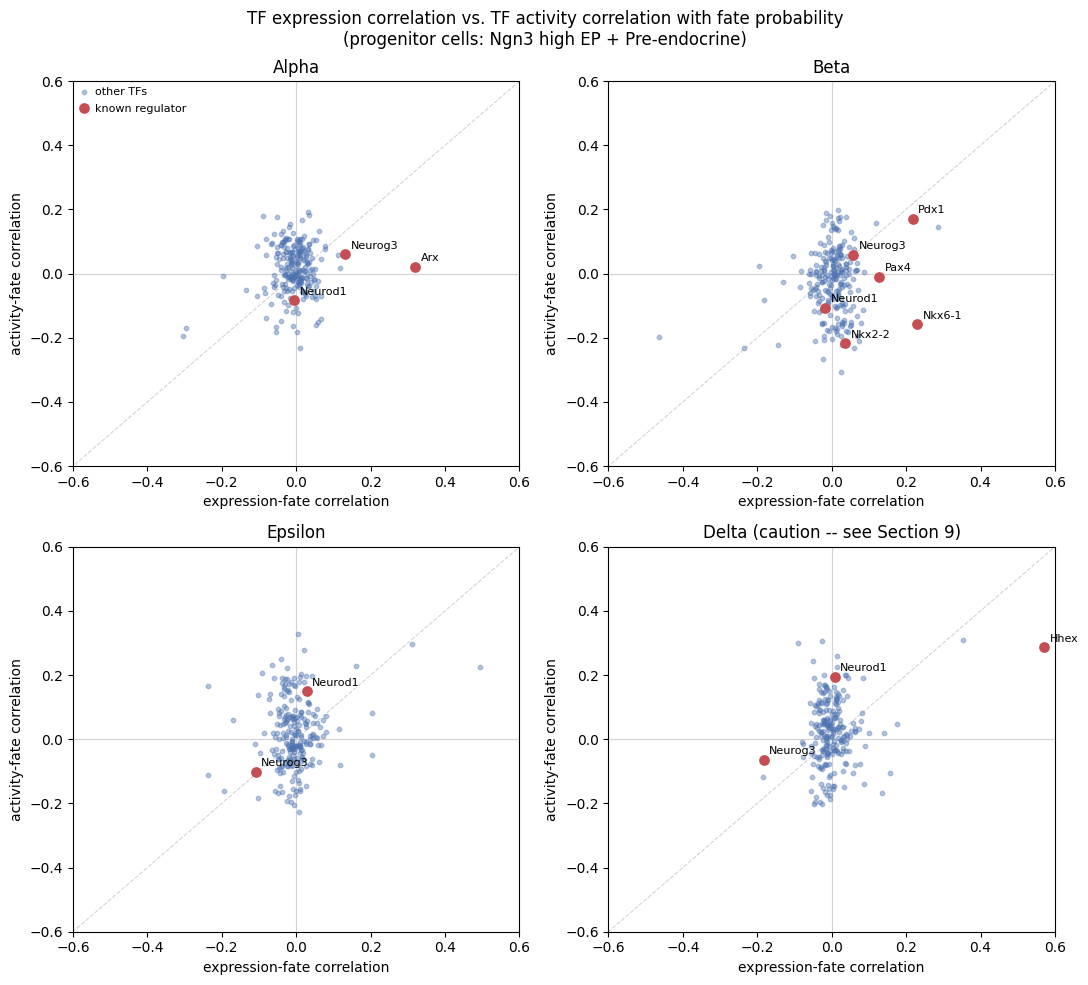

In [13]:
fig, axes = plt.subplots(2, 2, figsize=(11, 10))
plot_lineages = ["Alpha", "Beta", "Epsilon", "Delta"]

for ax, lineage in zip(axes.ravel(), plot_lineages):
    df = views[lineage]
    ax.axhline(0, color="lightgray", lw=0.8, zorder=0)
    ax.axvline(0, color="lightgray", lw=0.8, zorder=0)
    lims = [-1, 1]
    ax.plot(lims, lims, color="lightgray", lw=0.8, ls="--", zorder=0)

    known_mask = df["is_known_regulator"]
    ax.scatter(df.loc[~known_mask, "expr_corr"], df.loc[~known_mask, "activity_corr"],
               s=10, alpha=0.4, color="#4C72B0", label="other TFs")
    ax.scatter(df.loc[known_mask, "expr_corr"], df.loc[known_mask, "activity_corr"],
               s=45, color="#C44E52", zorder=3, label="known regulator")
    for gene in df.index[known_mask]:
        ax.annotate(gene, (df.loc[gene, "expr_corr"], df.loc[gene, "activity_corr"]),
                    fontsize=8, xytext=(4, 4), textcoords="offset points")

    title = lineage if lineage != "Delta" else "Delta (caution -- see Section 9)"
    ax.set_title(title)
    ax.set_xlabel("expression-fate correlation")
    ax.set_ylabel("activity-fate correlation")
    ax.set_xlim(-0.6, 0.6)
    ax.set_ylim(-0.6, 0.6)

axes[0, 0].legend(loc="upper left", fontsize=8)
fig.suptitle("TF expression correlation vs. TF activity correlation with fate probability\n(progenitor cells: Ngn3 high EP + Pre-endocrine)")
fig.tight_layout()
fig.savefig(FIG_DIR / "10_tf_expression_vs_activity_correlation.png", dpi=150, bbox_inches="tight")
plt.show()

## 6. Agreement between the two views

We summarize agreement with the Spearman correlation between expression-correlation and
activity-correlation, across all common TFs, per lineage. **Delta is reported separately in
Section 9 and excluded from this headline summary.**

In [14]:
print("Spearman correlation between expression-view and activity-view (headline lineages only):")
agreement = {}
for lineage in HEADLINE_LINEAGES:
    df = views[lineage]
    rho, pval = ss.spearmanr(df["expr_corr"], df["activity_corr"])
    agreement[lineage] = (rho, pval)
    print(f"  {lineage}: Spearman rho = {rho:.3f} (p = {pval:.2e}, n = {len(df)} TFs)")

Spearman correlation between expression-view and activity-view (headline lineages only):
  Alpha: Spearman rho = 0.006 (p = 9.31e-01, n = 232 TFs)
  Beta: Spearman rho = 0.043 (p = 5.16e-01, n = 232 TFs)
  Epsilon: Spearman rho = 0.053 (p = 4.22e-01, n = 232 TFs)


### A fairer agreement check

The overall Spearman above treats every TF identically, including many whose correlation (in
either view) is indistinguishable from noise -- diluting any real agreement signal towards zero.
Two sharper checks:

**(a) Restrict to TFs significant in either view** (FDR < 0.05 for the expression correlation, the
activity correlation, or both), then recompute the Spearman correlation and the **sign
concordance** (the fraction of these TFs where the two views at least agree on the *direction* of
the effect, even if not the magnitude).

**(b) Top-20 overlap.** Take the 20 TFs most positively correlated by each view separately, and
check how many appear in both top-20 lists. We test whether that overlap is bigger than chance with
a **permutation test**: redraw a random set of 20 TFs (from the same pool) 10,000 times and compare
the observed overlap with the expression-view top-20 to the resulting null distribution.

In [15]:
def sign_concordance(df):
    s = np.sign(df["expr_corr"]) * np.sign(df["activity_corr"])
    return (s > 0).mean()


def top20_overlap_permutation(df, n_perm=10000, seed=0):
    rng = np.random.default_rng(seed)
    top20_expr = set(df.sort_values("expr_corr", ascending=False).head(20).index)
    top20_activity_observed = set(df.sort_values("activity_corr", ascending=False).head(20).index)
    observed_overlap = len(top20_expr & top20_activity_observed)

    tfs = df.index.to_numpy()
    perm_overlaps = np.empty(n_perm, dtype=int)
    for i in range(n_perm):
        shuffled_top20 = set(rng.choice(tfs, size=20, replace=False))
        perm_overlaps[i] = len(top20_expr & shuffled_top20)
    pval = (1 + np.sum(perm_overlaps >= observed_overlap)) / (n_perm + 1)
    return observed_overlap, pval, sorted(top20_expr & top20_activity_observed)


print("Fairer agreement check (restricted to significant TFs; top-20 overlap with permutation p):")
fairer_agreement = {}
for lineage in HEADLINE_LINEAGES:
    df = views[lineage]
    sig_mask = (df["expr_qval"] < 0.05) | (df["activity_qval"] < 0.05)
    df_sig = df[sig_mask]
    if len(df_sig) >= 3:
        rho_sig, pval_sig = ss.spearmanr(df_sig["expr_corr"], df_sig["activity_corr"])
        concordance = sign_concordance(df_sig)
    else:
        rho_sig, pval_sig, concordance = np.nan, np.nan, np.nan

    overlap, overlap_pval, overlap_genes = top20_overlap_permutation(df)

    fairer_agreement[lineage] = {
        "n_significant": len(df_sig), "spearman_sig": rho_sig, "spearman_sig_pval": pval_sig,
        "sign_concordance_sig": concordance, "top20_overlap": overlap,
        "top20_overlap_pval": overlap_pval, "top20_overlap_genes": overlap_genes,
    }
    print(f"\n{lineage}:")
    print(f"  TFs significant (FDR<0.05) in either view: {len(df_sig)} / {len(df)}")
    if len(df_sig) >= 3:
        print(f"  Spearman among significant TFs: rho={rho_sig:.3f} (p={pval_sig:.2e})")
        print(f"  Sign concordance among significant TFs: {concordance:.1%}")
    else:
        print("  (too few significant TFs for a meaningful restricted Spearman)")
    print(f"  Top-20 overlap: {overlap} / 20 TFs shared, permutation p = {overlap_pval:.4f}")
    print(f"  Overlapping TFs: {overlap_genes}")

Fairer agreement check (restricted to significant TFs; top-20 overlap with permutation p):

Alpha:
  TFs significant (FDR<0.05) in either view: 100 / 232
  Spearman among significant TFs: rho=-0.016 (p=8.72e-01)
  Sign concordance among significant TFs: 55.0%
  Top-20 overlap: 1 / 20 TFs shared, permutation p = 0.8490
  Overlapping TFs: ['Smad1']



Beta:
  TFs significant (FDR<0.05) in either view: 120 / 232
  Spearman among significant TFs: rho=-0.014 (p=8.80e-01)
  Sign concordance among significant TFs: 46.7%
  Top-20 overlap: 3 / 20 TFs shared, permutation p = 0.2457
  Overlapping TFs: ['Fos', 'Mnx1', 'Pdx1']

Epsilon:
  TFs significant (FDR<0.05) in either view: 129 / 232
  Spearman among significant TFs: rho=0.084 (p=3.47e-01)
  Sign concordance among significant TFs: 50.4%
  Top-20 overlap: 3 / 20 TFs shared, permutation p = 0.2414
  Overlapping TFs: ['Arx', 'Fhl2', 'Isl1']


**What this shows.** The "fairer" check doesn't rescue agreement -- if anything it confirms the
two views are independent even where each is individually confident:

| Lineage | n significant (either view) | Spearman (significant only) | Sign concordance | Top-20 overlap | Permutation p |
|---|---|---|---|---|---|
| Alpha | 100 / 232 | -0.016 (p=0.87) | 55.0% | 1 / 20 | 0.849 |
| Beta | 120 / 232 | -0.014 (p=0.88) | 46.7% | 3 / 20 | 0.246 |
| Epsilon | 129 / 232 | 0.084 (p=0.35) | 50.4% | 3 / 20 | 0.241 |

Restricting to TFs with a statistically confident correlation in at least one view doesn't produce
a cleaner signal -- the restricted Spearman is still indistinguishable from zero (and for Beta is
mildly *negative*), sign concordance sits at or below the 50% coin-flip baseline for Alpha and
Beta, and none of the top-20 overlaps beat random chance (all permutation p > 0.24). **Hypothesis:**
this is genuine evidence that, in this system, a TF's progenitor-stage expression level and its
CollecTRI-inferred activity are telling largely unrelated stories -- not an artifact of noisy,
non-significant TFs diluting a real underlying signal.

In [16]:
print("Top TFs where the two views clearly disagree (headline lineages only, by |expr_corr - activity_corr|):")
disagreements = {}
for lineage in HEADLINE_LINEAGES:
    df = views[lineage].copy()
    df["abs_disagreement"] = (df["expr_corr"] - df["activity_corr"]).abs()
    top = df.sort_values("abs_disagreement", ascending=False).head(10)
    disagreements[lineage] = top
    print(f"\n{lineage}:")
    print(top[["expr_corr", "activity_corr", "abs_disagreement", "is_known_regulator"]])

Top TFs where the two views clearly disagree (headline lineages only, by |expr_corr - activity_corr|):

Alpha:
        expr_corr  activity_corr  abs_disagreement  is_known_regulator
Arx      0.320581       0.021076          0.299504                True
Nkx6-1  -0.090427       0.180700          0.271128               False
Pax4     0.011423      -0.230340          0.241763               False
Fosb    -0.052539       0.176593          0.229132               False
Hes1     0.053947      -0.159514          0.213461               False
Sfpq     0.058272      -0.150542          0.208814               False
Nono     0.065351      -0.141903          0.207254               False
Vdr     -0.106283       0.085703          0.191986               False
Fos     -0.196999      -0.006673          0.190326               False
Zfp148  -0.081488       0.108618          0.190106               False

Beta:
         expr_corr  activity_corr  abs_disagreement  is_known_regulator
Nkx6-1    0.229963      -0.15

## 7. Disagreement analysis

For each strong disagreement flagged above, we check a few structural clues and assign a
**hypothesis** -- these are plausible explanations the data is consistent with, not confirmed
mechanisms:

- **few curated targets** -- the TF has very few target genes in CollecTRI that are also present
  in our dataset, so its activity score is estimated from very little information.
- **TF acting in a different lineage** -- the TF's activity correlates much more strongly with a
  *different* fate than the one we're looking at, suggesting the expression correlation we see
  here might be a side effect of co-expression rather than a real role in this lineage.
- **naming/orthology issue** -- this mouse gene symbol came from a one-to-many human→mouse
  ortholog mapping (ambiguous orthology), so the "TF" in our network may not be the exact
  regulatory ortholog of the original human CollecTRI entry.
- **database gap / post-transcriptional regulation** -- our default fallback when no structural
  clue applies: CollecTRI may simply be missing the relevant edges for this TF in this context, or
  the TF's activity is regulated after transcription (phosphorylation, nuclear localization, etc.)
  in a way that decouples its own mRNA level from its targets' expression.

In [17]:
# Count of curated targets actually usable per TF (present in our 7197-gene dataset) -- this
# is what `tmin` filtered on, but the raw count (vs. the tmin=5 cutoff) is informative here.
targets_per_tf = (
    mouse_net[mouse_net["target"].isin(dataset_genes)]
    .groupby("source")["target"]
    .nunique()
)

# TFs produced by an ambiguous (one-to-many) human->mouse ortholog mapping: more than one human
# source symbol maps to this mouse symbol.
human_net_check = dc.op.collectri(organism="human")
hcop_url = "https://storage.googleapis.com/public-download-files/hcop/human_mouse_hcop_fifteen_column.txt.gz"
map_df_check = pd.read_csv(hcop_url, sep="\t", low_memory=False)
map_df_check["evidence"] = map_df_check["support"].apply(lambda x: len(str(x).split(",")))
map_df_check = map_df_check[map_df_check["evidence"] >= 3]
mouse_tf_ambiguous = set(
    map_df_check.groupby("mouse_symbol")["human_symbol"].nunique().loc[lambda s: s > 1].index
)


def explain_disagreement(gene, lineage, df_row, all_views):
    reasons = []
    n_targets = targets_per_tf.get(gene, 0)
    if n_targets < 10:
        reasons.append(f"few curated targets (n={n_targets})")
    other_lineages = [l for l in HEADLINE_LINEAGES if l != lineage]
    best_other, best_other_val = None, 0.0
    for other in other_lineages:
        other_activity_corr = all_views[other].loc[gene, "activity_corr"] if gene in all_views[other].index else np.nan
        if pd.notna(other_activity_corr) and abs(other_activity_corr) > abs(df_row["activity_corr"]) and abs(other_activity_corr) > abs(best_other_val):
            best_other, best_other_val = other, other_activity_corr
    if best_other is not None:
        reasons.append(f"TF activity correlates more strongly with {best_other} (r={best_other_val:.2f})")
    if gene in mouse_tf_ambiguous:
        reasons.append("naming/orthology issue (ambiguous one-to-many human->mouse mapping)")
    if not reasons:
        reasons.append("database gap or post-transcriptional regulation (no structural clue found)")
    return "; ".join(reasons)


disagreement_tables = {}
for lineage in HEADLINE_LINEAGES:
    top = disagreements[lineage].copy()
    top["n_targets"] = [targets_per_tf.get(g, 0) for g in top.index]
    top["reliable (>=10 targets)"] = top["n_targets"] >= 10
    top["hypothesis (unverified)"] = [
        explain_disagreement(gene, lineage, top.loc[gene], views) for gene in top.index
    ]
    disagreement_tables[lineage] = top
    print(f"\n=== {lineage}: disagreement hypotheses ===")
    print(top[["expr_corr", "activity_corr", "n_targets", "reliable (>=10 targets)", "hypothesis (unverified)"]].to_string())


=== Alpha: disagreement hypotheses ===
        expr_corr  activity_corr  n_targets  reliable (>=10 targets)                                                     hypothesis (unverified)
Arx      0.320581       0.021076         17                     True                  TF activity correlates more strongly with Epsilon (r=0.23)
Nkx6-1  -0.090427       0.180700         12                     True  database gap or post-transcriptional regulation (no structural clue found)
Pax4     0.011423      -0.230340          7                    False                                                   few curated targets (n=7)
Fosb    -0.052539       0.176593          8                    False                                                   few curated targets (n=8)
Hes1     0.053947      -0.159514         40                     True  database gap or post-transcriptional regulation (no structural clue found)
Sfpq     0.058272      -0.150542         15                     True  database gap or post

## 8. Does TF activity separate Alpha from Epsilon better than expression?

Notebook 2 found ***Arx*** as the #1 progenitor-restricted driver for **both** Alpha and
Epsilon -- a single gene can't mechanistically drive two different fates at once, so either Arx
really is a shared early regulator that later diverges, or expression correlation alone can't
tell the two lineages apart here. We check whether **activity** (which accounts for *which*
downstream genes are actually moving, not just Arx's own expression level) gives a cleaner
separation between the two fates than raw expression does.

In [18]:
arx_alpha_expr = views["Alpha"].loc["Arx", "expr_corr"] if "Arx" in views["Alpha"].index else np.nan
arx_epsilon_expr = views["Epsilon"].loc["Arx", "expr_corr"] if "Arx" in views["Epsilon"].index else np.nan
arx_alpha_act = views["Alpha"].loc["Arx", "activity_corr"] if "Arx" in views["Alpha"].index else np.nan
arx_epsilon_act = views["Epsilon"].loc["Arx", "activity_corr"] if "Arx" in views["Epsilon"].index else np.nan

print("Arx correlation with Alpha vs. Epsilon fate probability (progenitor cells):")
print(f"  Expression view:  Alpha r={arx_alpha_expr:.3f}   Epsilon r={arx_epsilon_expr:.3f}   |difference|={abs(arx_alpha_expr - arx_epsilon_expr):.3f}")
print(f"  Activity view:    Alpha r={arx_alpha_act:.3f}   Epsilon r={arx_epsilon_act:.3f}   |difference|={abs(arx_alpha_act - arx_epsilon_act):.3f}")

if abs(arx_alpha_act - arx_epsilon_act) > abs(arx_alpha_expr - arx_epsilon_expr):
    print("\n-> TF activity separates Alpha from Epsilon MORE than expression does.")
else:
    print("\n-> TF activity does NOT separate Alpha from Epsilon better than expression -- the ambiguity persists in both views.")

Arx correlation with Alpha vs. Epsilon fate probability (progenitor cells):
  Expression view:  Alpha r=0.321   Epsilon r=0.494   |difference|=0.174
  Activity view:    Alpha r=0.021   Epsilon r=0.227   |difference|=0.205

-> TF activity separates Alpha from Epsilon MORE than expression does.


### How many CollecTRI targets does Arx actually have here?

Before trusting Arx's activity score, we check how many of its curated targets are even
measurable in our data, and whether its regulatory logic (activating vs. repressing) is balanced
or skewed.

In [19]:
arx_edges_all = mouse_net[mouse_net["source"] == "Arx"]
arx_edges_in_data = arx_edges_all[arx_edges_all["target"].isin(dataset_genes)]

print(f"Arx: {len(arx_edges_all)} total CollecTRI edges (genome-wide)")
print(f"Arx: {len(arx_edges_in_data)} of those targets are present in our 7197-gene dataset")
print(f"  activating (weight > 0): {(arx_edges_in_data['weight'] > 0).sum()}")
print(f"  repressing (weight < 0): {(arx_edges_in_data['weight'] < 0).sum()}")
if len(arx_edges_in_data) < 10:
    print("  -> fewer than 10 targets present: Arx's activity score here should be treated as UNRELIABLE.")
else:
    print(f"  -> {len(arx_edges_in_data)} targets present: above the 10-target reliability threshold used elsewhere in this notebook.")

Arx: 29 total CollecTRI edges (genome-wide)
Arx: 17 of those targets are present in our 7197-gene dataset
  activating (weight > 0): 15
  repressing (weight < 0): 2
  -> 17 targets present: above the 10-target reliability threshold used elsewhere in this notebook.


**What this means.** Activity does separate Alpha from Epsilon slightly more than expression
(|difference| 0.205 vs. 0.174), but the more informative result is *how* the two views disagree,
not just the size of the gap. Under the **expression** view, Arx looks like a plausible positive
driver of *both* fates (r = 0.32 for Alpha, r = 0.49 for Epsilon) -- genuinely ambiguous. Under the
**activity** view, Arx's correlation with Alpha essentially vanishes (r = 0.02, indistinguishable
from noise) while a moderate positive correlation with Epsilon remains (r = 0.23). That's a more
specific claim than "activity separates better": it suggests Arx's *curated downstream targets*
only show the expected activation pattern along the Epsilon trajectory, and its apparent
association with Alpha commitment is likely driven by co-expression (Arx mRNA happening to be
present) rather than Arx actually engaging its regulatory program there.

This reading is on firmer footing than most of this notebook's other activity-based claims: Arx has
**17 curated targets present in our dataset** (29 genome-wide), well above the 10-target
reliability threshold used elsewhere, and 15 of those 17 are activating edges (only 2 repressing)
-- a reasonably well-powered, directionally consistent regulon to estimate activity from. Still a
**hypothesis**, resting on one TF pair and on CollecTRI's curated Arx targets being relevant to
this specific developmental system, not a settled mechanism.

## 9. Delta — separate, caveated section

Everything in this section uses the **same two-view computation** as above, but for Delta
specifically, and it is kept **out of** the headline agreement numbers in Sections 6-7 for a
concrete reason: Delta's progenitor fate probability is tiny (roughly 0.001-0.03 across
Ngn3 high EP / Pre-endocrine cells, per notebook 2), and Delta itself has only 70 cells in the
entire 3696-cell dataset. A Pearson correlation against a variable that barely varies is
statistically fragile -- small absolute changes can produce large relative swings in the
correlation coefficient, and single outlier cells can dominate. Treat everything below as
suggestive, not confirmatory.

In [20]:
print("Delta: Spearman agreement between expression-view and activity-view")
rho, pval = ss.spearmanr(views["Delta"]["expr_corr"], views["Delta"]["activity_corr"])
print(f"  Spearman rho = {rho:.3f} (p = {pval:.2e}, n = {len(views['Delta'])} TFs)")

print("\nDelta: top driver genes/TFs by expression correlation, with their activity-view counterpart")
views["Delta"].sort_values("expr_corr", ascending=False).head(10)

Delta: Spearman agreement between expression-view and activity-view
  Spearman rho = 0.061 (p = 3.52e-01, n = 232 TFs)

Delta: top driver genes/TFs by expression correlation, with their activity-view counterpart


,expr_corr,expr_qval,activity_corr,activity_pval,activity_qval,is_known_regulator
Hhex,0.571307,4.459746e-111,0.286924,8.150738e-25,4.727428e-23,True
Isl1,0.351962,8.044803e-35,0.309048,1.017875e-28,2.361471e-26,False
Id2,0.175904,9.901933e-08,0.046551,1.021584e-01,1.680904e-01,False
Foxo1,0.156901,4.206671e-06,-0.104243,2.442887e-04,7.084373e-04,False
Pdx1,0.140137,8.354414e-05,0.018446,5.173802e-01,5.942188e-01,False
Fos,0.134261,2.139650e-04,-0.166792,3.757440e-09,3.228615e-08,False
Egr1,0.101168,1.494727e-02,0.020085,4.808650e-01,5.691871e-01,False
Mlxipl,0.088741,4.927301e-02,-0.021291,4.549211e-01,5.440293e-01,False
Atf3,0.086455,5.942667e-02,-0.139908,8.053950e-07,3.813299e-06,False
Pax6,0.083979,7.448598e-02,0.191725,1.111549e-11,1.516938e-10,False


In [21]:
print("Delta: fairer agreement check (same method as the headline lineages; interpret cautiously)")
df_delta = views["Delta"]
sig_mask = (df_delta["expr_qval"] < 0.05) | (df_delta["activity_qval"] < 0.05)
df_delta_sig = df_delta[sig_mask]
if len(df_delta_sig) >= 3:
    rho_sig, pval_sig = ss.spearmanr(df_delta_sig["expr_corr"], df_delta_sig["activity_corr"])
    concordance = sign_concordance(df_delta_sig)
    print(f"  TFs significant (FDR<0.05) in either view: {len(df_delta_sig)} / {len(df_delta)}")
    print(f"  Spearman among significant TFs: rho={rho_sig:.3f} (p={pval_sig:.2e})")
    print(f"  Sign concordance among significant TFs: {concordance:.1%}")
else:
    print(f"  Only {len(df_delta_sig)} TFs significant in either view -- too few for a meaningful restricted Spearman.")

overlap, overlap_pval, overlap_genes = top20_overlap_permutation(df_delta)
print(f"  Top-20 overlap: {overlap} / 20 TFs shared, permutation p = {overlap_pval:.4f}")
print(f"  Overlapping TFs: {overlap_genes}")

Delta: fairer agreement check (same method as the headline lineages; interpret cautiously)
  TFs significant (FDR<0.05) in either view: 118 / 232
  Spearman among significant TFs: rho=0.099 (p=2.85e-01)
  Sign concordance among significant TFs: 55.1%


  Top-20 overlap: 3 / 20 TFs shared, permutation p = 0.2443


  Overlapping TFs: ['Hhex', 'Isl1', 'Pax6']


In [22]:
print("Delta: top disagreements between expression and activity views")
delta_df = views["Delta"].copy()
delta_df["abs_disagreement"] = (delta_df["expr_corr"] - delta_df["activity_corr"]).abs()
delta_df["n_targets"] = [targets_per_tf.get(g, 0) for g in delta_df.index]
delta_df["reliable (>=10 targets)"] = delta_df["n_targets"] >= 10
delta_top_disagreement = delta_df.sort_values("abs_disagreement", ascending=False).head(10)
delta_top_disagreement[["expr_corr", "activity_corr", "abs_disagreement", "n_targets", "reliable (>=10 targets)", "is_known_regulator"]]

Delta: top disagreements between expression and activity views


,expr_corr,activity_corr,abs_disagreement,n_targets,reliable (>=10 targets),is_known_regulator
Pax4,-0.089444,0.299301,0.388744,7,False,False
Apex1,-0.026820,0.304928,0.331748,18,True,False
Fos,0.134261,-0.166792,0.301053,112,True,False
Nono,-0.049898,0.243015,0.292913,8,False,False
Hhex,0.571307,0.286924,0.284383,10,True,True
Foxo1,0.156901,-0.104243,0.261144,103,True,False
Ssrp1,0.013102,0.258655,0.245553,52,True,False
Sfpq,-0.047310,0.192033,0.239343,15,True,False
Atf3,0.086455,-0.139908,0.226364,44,True,False
Hipk2,-0.020633,0.201134,0.221767,5,False,False


**Hhex** (the one literature-fixed Delta regulator) should be checked here explicitly, given
how small and noisy Delta's signal is overall.

In [23]:
if "Hhex" in views["Delta"].index:
    row = views["Delta"].loc["Hhex"]
    rank, corr = driver_rank("Hhex", "Delta")
    print(f"Hhex: driver-list rank for Delta = {rank} (of {driver_df.shape[0]} genes), expr_corr = {corr:.3f}, activity_corr = {row['activity_corr']:.3f}")
else:
    print("Hhex did not survive the ULM tmin filter (fewer than 5 curated targets present in the dataset) -- no activity score available.")

Hhex: driver-list rank for Delta = 1 (of 7197 genes), expr_corr = 0.571, activity_corr = 0.287


## 10. Known regulators recovered — consolidated table

In [24]:
rows = []
for lineage, genes in KNOWN_REGULATORS.items():
    for gene in genes:
        in_dataset = gene in dataset_genes
        in_collectri = gene in net_tfs
        rank, expr_corr_val = driver_rank(gene, lineage)
        activity_corr_val = views[lineage].loc[gene, "activity_corr"] if (lineage in views and gene in views[lineage].index) else np.nan
        rows.append({
            "lineage": lineage,
            "gene": gene,
            "in_dataset": in_dataset,
            "in_collectri": in_collectri,
            "driver_rank": rank,
            "expr_corr": expr_corr_val,
            "activity_corr": activity_corr_val,
        })
recovered_table = pd.DataFrame(rows)
recovered_table

,lineage,gene,in_dataset,in_collectri,driver_rank,expr_corr,activity_corr
0,Beta,Pdx1,True,True,8.0,0.218036,0.171014
1,Beta,Nkx6-1,True,True,6.0,0.229963,-0.158155
2,Beta,Mafa,False,True,NaN,NaN,NaN
3,Beta,Pax4,True,True,40.0,0.126793,-0.009662
4,Beta,Nkx2-2,True,True,1076.0,0.036603,-0.217397
5,Alpha,Arx,True,True,1.0,0.320581,0.021076
6,Alpha,Mafb,False,True,NaN,NaN,NaN
7,Alpha,Irx1,False,True,NaN,NaN,NaN
8,Alpha,Irx2,True,True,90.0,0.092133,NaN
9,Alpha,Pou3f4,False,True,NaN,NaN,NaN


## 11. Sensitivity check: does the full gene panel change the agreement numbers?

Everything above used the 7197-gene panel that survived notebook 1's `min_shared_counts=20`
velocity filter. Section 2 showed that filter can drop genes for reasons unrelated to expression
level (zero unspliced counts), which could also affect ULM's activity estimates for TFs whose
curated targets were disproportionately filtered out. We re-run ULM on the **full** gene panel
(raw counts, normalized and log-transformed the same way, same 3696 cells) -- no other parameter
changed -- restricted to the *same* TFs used throughout this notebook, and compare the Section 6
agreement numbers directly.

In [25]:
full_adata = raw.copy()  # same 3696 cells, full ~28,000-gene panel, no min_shared_counts filter
scv.pp.normalize_per_cell(full_adata)
sc.pp.log1p(full_adata)

dc.mt.ulm(full_adata, net=mouse_net, tmin=5, verbose=False)
activity_full = full_adata.obsm["score_ulm"]
print(f"TFs with an activity score on the full gene panel: {activity_full.shape[1]} (vs. {activity.shape[1]} on the 7197-gene panel)")

common_tfs_in_full = [tf for tf in common_tfs if tf in activity_full.columns]
print(f"Of the original {len(common_tfs)} common TFs, {len(common_tfs_in_full)} also have a full-panel activity score")

newly_available = sorted({"Mafb", "Irx1", "Pou3f4"} & set(activity_full.columns))
print(f"Previously-missing known regulators now measurable on the full panel: {newly_available if newly_available else 'none'}")

Normalized count data: X, spliced, unspliced.


TFs with an activity score on the full gene panel: 724 (vs. 510 on the 7197-gene panel)
Of the original 232 common TFs, 232 also have a full-panel activity score
Previously-missing known regulators now measurable on the full panel: ['Irx1', 'Mafb']


In [26]:
full_views = {}
for lineage in HEADLINE_LINEAGES:
    fate_vec = fate_probs.loc[progenitor_mask, lineage].to_numpy()
    act_r = {tf: ss.pearsonr(activity_full.loc[progenitor_mask, tf].to_numpy(), fate_vec)[0] for tf in common_tfs_in_full}
    df = views[lineage].loc[common_tfs_in_full, ["expr_corr", "expr_qval"]].copy()
    df["activity_corr_full"] = pd.Series(act_r)
    full_views[lineage] = df

print("Agreement numbers: original (7197-gene) panel vs. full-gene-panel ULM, same TFs:")
sensitivity_summary = {}
for lineage in HEADLINE_LINEAGES:
    df = full_views[lineage]
    rho_orig, _ = ss.spearmanr(views[lineage].loc[df.index, "expr_corr"], views[lineage].loc[df.index, "activity_corr"])
    rho_full, _ = ss.spearmanr(df["expr_corr"], df["activity_corr_full"])

    sig_mask_full = (df["expr_qval"] < 0.05)  # expr side unchanged; activity significance recomputed below
    act_pvals_full = {tf: ss.pearsonr(activity_full.loc[progenitor_mask, tf].to_numpy(), fate_probs.loc[progenitor_mask, lineage].to_numpy())[1] for tf in df.index}
    act_qvals_full = pd.Series(bh_fdr(pd.Series(act_pvals_full).loc[df.index].to_numpy()), index=df.index)
    sig_mask_full = sig_mask_full | (act_qvals_full < 0.05)
    df_sig_full = df[sig_mask_full]
    if len(df_sig_full) >= 3:
        rho_sig_full, _ = ss.spearmanr(df_sig_full["expr_corr"], df_sig_full["activity_corr_full"])
        conc_full = (np.sign(df_sig_full["expr_corr"]) * np.sign(df_sig_full["activity_corr_full"]) > 0).mean()
    else:
        rho_sig_full, conc_full = np.nan, np.nan

    top20_expr = set(df.sort_values("expr_corr", ascending=False).head(20).index)
    top20_act_full = set(df.sort_values("activity_corr_full", ascending=False).head(20).index)
    overlap_full = len(top20_expr & top20_act_full)

    sensitivity_summary[lineage] = {
        "rho_orig": rho_orig, "rho_full": rho_full,
        "rho_sig_full": rho_sig_full, "concordance_sig_full": conc_full,
        "n_sig_full": len(df_sig_full), "top20_overlap_full": overlap_full,
    }
    print(f"\n{lineage}:")
    print(f"  Naive Spearman:        7197-gene panel = {rho_orig:.3f}   full panel = {rho_full:.3f}")
    print(f"  Significant-only (n={len(df_sig_full)}): Spearman = {rho_sig_full:.3f}, sign concordance = {conc_full:.1%}" if len(df_sig_full) >= 3 else "  Significant-only: too few significant TFs")
    print(f"  Top-20 overlap (full panel): {overlap_full} / 20")

Agreement numbers: original (7197-gene) panel vs. full-gene-panel ULM, same TFs:

Alpha:
  Naive Spearman:        7197-gene panel = 0.006   full panel = 0.028
  Significant-only (n=100): Spearman = -0.033, sign concordance = 56.0%
  Top-20 overlap (full panel): 2 / 20



Beta:
  Naive Spearman:        7197-gene panel = 0.043   full panel = 0.049
  Significant-only (n=114): Spearman = -0.017, sign concordance = 48.2%
  Top-20 overlap (full panel): 3 / 20

Epsilon:
  Naive Spearman:        7197-gene panel = 0.053   full panel = 0.070
  Significant-only (n=121): Spearman = 0.096, sign concordance = 52.9%
  Top-20 overlap (full panel): 3 / 20


**What this shows.** The full gene panel barely moves any of the Section 6 numbers:

| Lineage | Naive Spearman (7197-gene) | Naive Spearman (full panel) | Significant-only Spearman (full) | Sign concordance (full) | Top-20 overlap (full) |
|---|---|---|---|---|---|
| Alpha | 0.006 | 0.028 | -0.033 (n=100) | 56.0% | 2 / 20 |
| Beta | 0.043 | 0.049 | -0.017 (n=114) | 48.2% | 3 / 20 |
| Epsilon | 0.053 | 0.070 | 0.096 (n=121) | 52.9% | 3 / 20 |

Every number is within noise of its 7197-gene-panel counterpart from Sections 6-7. **This is a
meaningful negative result**: it rules out "the weak agreement is just an artifact of notebook 1's
velocity-specific gene filter dropping relevant target genes" as an explanation. The disagreement
between expression and activity views looks like a property of this comparison in this system (or
of how well CollecTRI's curated edges transfer to it), not a side effect of which genes happened to
survive preprocessing.

One side note from using the full panel: of the three known regulators missing from the 7197-gene
panel, **Irx1 and Mafb** now get an activity score (their regulons have enough targets once the
full gene panel is available), but **Pou3f4 still doesn't** -- its CollecTRI regulon apparently has
fewer than 5 targets even genome-wide in this expression matrix, which is a different, more
fundamental data limitation than the splicing-filter issue affecting Irx1/Mafb (Section 2).

## Summary

**Coverage.** Mouse CollecTRI (via the corrected HCOP URL, saved to `results/collectri_mouse.csv`)
has 1165 TFs and 43,226 edges; 2619 of our 7197 dataset genes appear as curated targets, and 488
are themselves CollecTRI TFs. 510 TFs had enough measured targets (`tmin=5`) for a ULM activity
score on the 7197-gene panel, and 232 of those were usable for the full two-view comparison.

**Known regulators: recovered by expression, barely by activity.** By *expression* correlation,
the literature-fixed regulators mostly do well -- *Arx* and *Hhex* are the #1 drivers for Alpha and
Delta, *Nkx6-1*/*Pdx1* are top-10 for Beta -- though *Nkx2-2* (a well-established beta regulator)
ranks 1076th of 7197, a reminder that expression correlation with eventual fate is not the same as
developmental necessity. By *activity* correlation, agreement with the literature mostly evaporates:
*Nkx6-1* and *Nkx2-2*'s activity correlations with Beta are both **negative** despite positive
expression correlations. Four of eleven lineage-specific regulators (*Mafa, Mafb, Irx1, Pou3f4*)
aren't in the 7197-gene panel at all.

**Those four missing regulators are mostly a pipeline artifact, not a biological absence
(hypothesis, checked against raw data).** *Mafb* and *Pou3f4* have thousands of raw spliced counts
with clear, lineage-patterned expression (Mafb: 98% of Beta cells, 73% of Alpha cells; Pou3f4:
~50% of Pre-endocrine/Alpha/Epsilon cells) but **zero unspliced counts anywhere**, failing notebook
1's velocity-specific `min_shared_counts=20` filter outright. *Irx1* shows the same lineage-specific
pattern (72% of Alpha cells, 49% of Epsilon cells) with low but nonzero unspliced counts, just under
threshold. Only *Mafa* looks genuinely near-absent (1 read total in 3696 cells) -- plausibly because
it's a largely *postnatal* beta-maturation factor not yet active at this embryonic (E15.5) stage.
On the full gene panel (Section 11), Irx1 and Mafb do get an activity score; Pou3f4 still doesn't,
suggesting its CollecTRI regulon is simply too small (<5 targets) regardless of filtering.

**Agreement between the two views is weak -- and the fairer checks confirm this rather than
rescuing it.** The naive Spearman is ~0 for every headline lineage (Alpha 0.006, Beta 0.043,
Epsilon 0.053). Restricting to only the TFs significant (FDR<0.05) in either view doesn't help: the
restricted Spearman stays near zero (Alpha -0.016, Beta -0.014, Epsilon 0.084), **sign concordance
sits at or below the 50% coin-flip baseline for Alpha (55.0%) and especially Beta (46.7%)**, and the
top-20-by-each-view overlap is never more than 3 of 20 TFs, never beating random chance by a
permutation test (all p > 0.24). **Hypothesis:** the two views are measuring genuinely different
things in this system, not just disagreeing on a noisy minority of TFs.

**This isn't a gene-panel artifact (Section 11).** Re-running ULM on the full, unfiltered gene
panel (same cells, same net, same `tmin`) leaves every one of these numbers within noise of its
7197-gene-panel counterpart. Whatever is driving the weak agreement, it isn't which genes notebook
1's velocity filter happened to keep.

**The Arx case is the clearest positive result for activity inference (hypothesis, better-supported
than most).** Expression alone can't distinguish whether Arx drives Alpha, Epsilon, or both (r=0.32
and r=0.49). Its activity correlation drops to noise for Alpha (r=0.02) but stays positive for
Epsilon (r=0.23) -- and unlike many other disagreements in this notebook, Arx's activity estimate
rests on a reasonably sized, directionally consistent regulon (17 targets present in the dataset,
15 activating vs. 2 repressing), so "too few curated targets" can't explain this particular
disagreement away.

**What the other disagreements suggest.** Across the top disagreement candidates for Alpha/Beta/
Epsilon, several have fewer than 10 curated targets present in the data (flagged "unreliable" in
the tables above) -- a concrete data-quality limitation, not a biological claim. Several more show
activity correlating more strongly with a *different* lineage than the one being tested (e.g. *Arx*
and *Nkx2-2* both show stronger Beta-vs-Epsilon cross-talk), hinting at real cross-lineage signal.
No disagreement in this run traced to an ambiguous ortholog mapping. The rest fall into an
honestly-unresolved "database gap or post-transcriptional regulation" bucket.

**Delta, kept separate throughout, as before.** *Hhex* remains the #1 expression driver (0.57) with
a weaker positive activity correlation (0.29, 10 targets -- right at the reliability threshold).
Delta's own fairer-agreement numbers (118/232 significant, restricted Spearman 0.099, 55.1% sign
concordance, 3/20 top-20 overlap) look similar in kind to the headline lineages -- Delta isn't
behaving unusually *relative to the overall pattern*, but every one of its numbers is still built on
70 cells and near-zero progenitor fate-probability variance, so treat it as suggestive only.

**Limitations, restated.** Everything here is correlational; nothing establishes causation. CollecTRI's
edges were curated mostly from human studies across many tissues, translated to mouse by gene-symbol
orthology only (not re-verified biologically). ULM's activity score assumes a TF's curated targets
respond the way those other studies found; given how weak the overall expression/activity agreement
turned out to be -- and how robust that weakness was to both a stricter significance filter and a
completely different gene panel -- that assumption looks shakier here than one might have hoped
going in. Every specific explanation offered above (Arx/Epsilon, cross-lineage activity, filtering
artifacts) is a **hypothesis** consistent with the data, not a verified mechanism.